#Hands-on 3 Regresión Polinomial
**Caso de estudio:** relación entre el **tamaño de lote** (*Batch Size*) y la **eficiencia de la máquina** (*Machine Efficiency*).

**Objetivo:** mostrar, paso a paso, cómo ajustar una curva polinomial de grado $n > 3$ (aquí usaremos $n = 4$) mediante **mínimos cuadrados** (*Least Squares*), siguiendo todas las etapas de un *pipeline* de Machine Learning.


## 1. Fundamentos teóricos del *Least Squares Regressor* para el ajuste de curvas

### 1.1 ¿Qué es el ajuste de curvas?
Dado un conjunto de $m$ observaciones $\{(x_i, y_i)\}_{i=1}^{m}$, el ajuste de curvas busca una función $f(x;\boldsymbol\beta)$, definida por parámetros $\boldsymbol\beta$, que describa la tendencia de los datos:

$$y_i = f(x_i;\boldsymbol\beta) + \varepsilon_i$$

donde $\varepsilon_i$ es el **error** (ruido) de la observación $i$.

### 1.2 El criterio de mínimos cuadrados
El método de **mínimos cuadrados** (*Least Squares*, Gauss–Legendre) elige los parámetros que minimizan la **suma de los cuadrados de los residuos**:

$$S(\boldsymbol\beta)=\sum_{i=1}^{m}\big(y_i-f(x_i;\boldsymbol\beta)\big)^2=\sum_{i=1}^{m} e_i^2$$

¿Por qué al cuadrado?
- Evita que errores positivos y negativos se cancelen.
- Penaliza más los errores grandes.
- Es diferenciable, por lo que tiene solución analítica cuando el modelo es **lineal en los parámetros**.

### 1.3 ¿Por qué una regresión polinomial sigue siendo "lineal"?
Un polinomio de grado $n$,

$$f(x)=\beta_0+\beta_1x+\beta_2x^2+\dots+\beta_nx^n,$$

es **no lineal en $x$**, pero **lineal en los coeficientes $\beta_j$**. Si definimos las nuevas variables $x_1=x,\;x_2=x^2,\dots,x_n=x^n$, el problema se convierte en una **regresión lineal múltiple** y se resuelve con el mismo *Least Squares Regressor* (`LinearRegression` en scikit-learn). Esta transformación de variables se llama **expansión polinomial de características** (*polynomial feature expansion*).

### 1.4 Supuestos clásicos (Gauss–Markov)
1. El modelo es lineal en los parámetros.
2. Los errores tienen media cero: $E[\varepsilon_i]=0$.
3. Varianza constante (*homocedasticidad*): $\mathrm{Var}(\varepsilon_i)=\sigma^2$.
4. Los errores no están correlacionados entre sí.
5. (Para inferencia) los errores siguen una distribución normal.

Bajo los supuestos 1–4, el estimador de mínimos cuadrados es el **mejor estimador lineal insesgado** (BLUE).

### 1.5 Elección del grado: sesgo vs. varianza
- **Grado bajo** → *underfitting* (alto sesgo): la curva es demasiado rígida para capturar la tendencia.
- **Grado alto** → *overfitting* (alta varianza): la curva persigue el ruido y generaliza mal.

Por eso el grado $n$ es un **hiperparámetro** que se selecciona con **validación cruzada**.

## 2. Modelo matemático y analítico

### 2.1 Modelo polinomial de grado $n$
Para cada observación $i = 1,\dots,m$:

$$y_i=\beta_0+\beta_1x_i+\beta_2x_i^2+\dots+\beta_nx_i^n+\varepsilon_i$$

### 2.2 Forma matricial
Se construye la **matriz** $\mathbf{X}\in\mathbb{R}^{m\times(n+1)}$:

$$
\mathbf{X}=\begin{bmatrix}
1 & x_1 & x_1^2 & \cdots & x_1^n\\
1 & x_2 & x_2^2 & \cdots & x_2^n\\
\vdots & \vdots & \vdots & & \vdots\\
1 & x_m & x_m^2 & \cdots & x_m^n
\end{bmatrix},\quad
\mathbf{y}=\begin{bmatrix}y_1\\ \vdots\\ y_m\end{bmatrix},\quad
\boldsymbol\beta=\begin{bmatrix}\beta_0\\ \vdots\\ \beta_n\end{bmatrix}
$$

y el modelo queda: $\mathbf{y}=\mathbf{X}\boldsymbol\beta+\boldsymbol\varepsilon$.

### 2.3 Función de costo
$$S(\boldsymbol\beta)=\|\mathbf{y}-\mathbf{X}\boldsymbol\beta\|^2=(\mathbf{y}-\mathbf{X}\boldsymbol\beta)^\top(\mathbf{y}-\mathbf{X}\boldsymbol\beta)$$

### 2.4 Solución analítica: ecuaciones normales
Derivando respecto a $\boldsymbol\beta$ e igualando a cero:

$$\frac{\partial S}{\partial\boldsymbol\beta}=-2\mathbf{X}^\top\mathbf{y}+2\mathbf{X}^\top\mathbf{X}\boldsymbol\beta=\mathbf{0}
\;\;\Longrightarrow\;\;
\boxed{\mathbf{X}^\top\mathbf{X}\,\hat{\boldsymbol\beta}=\mathbf{X}^\top\mathbf{y}}$$

Si $\mathbf{X}^\top\mathbf{X}$ es invertible:

$$\hat{\boldsymbol\beta}=(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$$

> En la práctica, scikit-learn no invierte la matriz; usa descomposiciones numéricamente más estables (SVD / `lstsq`).

### 2.5 Consideración numérica importante
Las potencias $x, x^2,\dots,x^n$ están **fuertemente correlacionadas** (multicolinealidad) y tienen escalas muy distintas (con $x\approx 100$ y $n=4$, $x^4\approx10^8$). Esto vuelve a $\mathbf{X}^\top\mathbf{X}$ mal condicionada. **Solución:** estandarizar la variable antes de expandirla:

$$z=\frac{x-\bar{x}}{s_x}$$

y ajustar el polinomio en $z$. Esto no cambia la curva ajustada, pero mejora la estabilidad numérica.

### 2.6 Métricas de evaluación
Con $\hat{y}_i$ la predicción y $\bar y$ la media de $y$:

| Métrica | Fórmula | Interpretación |
|---|---|---|
| $R^2$ | $1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | Proporción de la varianza explicada (1 = ajuste perfecto) |
| $R^2$ ajustado | $1-(1-R^2)\dfrac{m-1}{m-p-1}$ | $R^2$ penalizado por el número de términos $p$ |
| RMSE | $\sqrt{\dfrac1m\sum(y_i-\hat y_i)^2}$ | Error típico, en las mismas unidades de $y$ |
| MAE | $\dfrac1m\sum\lvert y_i-\hat y_i\rvert$ | Error absoluto promedio |

## 3. Pipeline de Machine Learning

Etapas que seguiremos:

`Recolección de datos → Descripción/EDA → Scatter plot → Preparación → Entrenamiento → Evaluación → Predicción`

### Paso 0. Importar las librerías

In [ ]:
# Importamos NumPy: arreglos numéricos y álgebra lineal
import numpy as np
# Importamos pandas: manejo de datos tabulares (DataFrame)
import pandas as pd
# Importamos matplotlib: gráficos
import matplotlib.pyplot as plt
# Importamos train_test_split (partición), KFold (validación cruzada) y cross_val_score (puntuación por CV)
from sklearn.model_selection import train_test_split, KFold, cross_val_score
# Importamos PolynomialFeatures: genera x, x^2, ..., x^n a partir de x
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# Importamos LinearRegression: el regresor de mínimos cuadrados (Least Squares)
from sklearn.linear_model import LinearRegression
# Importamos Pipeline: encadena escalado -> expansión polinomial -> regresión en un solo objeto
from sklearn.pipeline import Pipeline
# Importamos las métricas de evaluación
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Fijamos una semilla para que los resultados sean reproducibles
SEED = 42
# Aplicamos un estilo de gráficos limpio
plt.style.use("seaborn-v0_8-whitegrid")

### 3.1 Recolección de datos

Los datos provienen de una tabla con **26 observaciones** de dos variables:

- `batch_size` (variable independiente, $x$): tamaño del lote.
- `machine_efficiency` (variable dependiente, $y$): eficiencia de la máquina (%).

Los transcribimos a un archivo CSV (`batch_efficiency.csv`). En **Google Colab**, el siguiente bloque abre un cuadro de diálogo para que subas el archivo; en **Jupyter local** basta con tenerlo en la misma carpeta.

In [ ]:
# Importamos os para comprobar si el archivo existe en el directorio de trabajo
import os
from google.colab import files
# Abrimos el diálogo para subir manualmente batch_efficiency.csv
files.upload()
# Leemos el CSV y lo guardamos en un DataFrame llamado df
df = pd.read_csv("batch_efficiency.csv")
# Mostramos las primeras 10 filas para verificar que la carga fue correcta
df.head(10)

Saving batch_efficiency.csv to batch_efficiency (1).csv


,batch_size,machine_efficiency
0,108,95
1,115,96
2,106,95
3,97,97
4,95,93
5,91,94
6,97,95
7,83,93
8,83,92
9,78,86


### 3.2 Descripción y análisis del dataset (EDA)

Antes de modelar hay que entender los datos: tamaño, tipos, valores faltantes, estadísticos y correlación.

In [ ]:
# Imprimimos el número de filas y columnas del dataset
print("Dimensiones (filas, columnas):", df.shape)
# Contamos los valores faltantes por columna (esperamos 0)
print("\nValores nulos por columna:\n", df.isnull().sum())
# Contamos las filas duplicadas exactas (informativo; no eliminamos datos)
print("\nFilas duplicadas:", df.duplicated().sum())

Dimensiones (filas, columnas): (26, 2)

Valores nulos por columna:
 batch_size            0
machine_efficiency    0
dtype: int64

Filas duplicadas: 1


In [ ]:
# Calculamos estadísticos descriptivos (media, desviación, mínimo, cuartiles, máximo)
df.describe().round(2)

,batch_size,machine_efficiency
count,26.00,26.00
mean,75.23,82.65
std,27.63,14.67
min,25.00,55.00
25%,54.50,70.00
50%,82.00,90.50
75%,96.50,94.75
max,115.00,97.00


### 3.3 Scatter plot

El diagrama de dispersión revela la **forma** de la relación y justifica (o no) el uso de un modelo no lineal.

In [ ]:
# Creamos una figura de 8x5 pulgadas
plt.figure(figsize=(8, 5))
# Dibujamos los puntos: eje X = tamaño de lote, eje Y = eficiencia
plt.scatter(df["batch_size"], df["machine_efficiency"], color="tab:blue", edgecolor="k", s=60, label="Datos observados")
# Etiqueta del eje X
plt.xlabel("Batch Size")
# Etiqueta del eje Y
plt.ylabel("Machine Efficiency (%)")
# Título del gráfico
plt.title("Scatter plot: Batch Size vs Machine Efficiency")
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

**Observación:** la eficiencia crece rápido con lotes pequeños y luego se **satura** (curva cóncava). Una recta no captura bien este comportamiento; un polinomio de grado superior es un candidato razonable.

### 3.4 Preparación de los datos

1. Separar la variable independiente $X$ (matriz de $m\times1$) de la dependiente $y$ (vector).
2. Dividir en **entrenamiento (80 %)** y **prueba (20 %)** para evaluar el modelo con datos que no vio al ajustarse.

> El escalado (estandarización) lo incluiremos **dentro del Pipeline**, de modo que sus parámetros (media y desviación) se calculen **solo con los datos de entrenamiento** y se evite *data leakage*.

In [ ]:
# X debe ser una matriz 2D (m filas x 1 columna), por eso usamos doble corchete y .values
X = df[["batch_size"]].values
# y es un vector 1D con la variable objetivo
y = df["machine_efficiency"].values

# Dividimos en entrenamiento (80 %) y prueba (20 %) con semilla fija para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

### 3.5 Entrenamiento del modelo (grado $n = 4$)

Construimos el *pipeline* final y lo ajustamos con los datos de entrenamiento. Internamente, `LinearRegression` resuelve el problema de mínimos cuadrados de la sección 2.

In [ ]:
# Fijamos el grado del polinomio
DEGREE = 4

# Construimos el pipeline final
model = Pipeline([
    # Paso 1: estandarizamos x -> z = (x - media) / desviación (parámetros aprendidos solo del train)
    ("scaler", StandardScaler()),
    # Paso 2: expandimos z a [z, z^2, z^3, z^4]
    ("poly", PolynomialFeatures(degree=DEGREE, include_bias=False)),
    # Paso 3: regresión lineal por mínimos cuadrados sobre las características expandidas
    ("lr", LinearRegression()),
])

# Entrenamos (ajustamos) el modelo con los datos de entrenamiento
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('poly', PolynomialFeatures(degree=4, include_bias=False)),
                ('lr', LinearRegression())])

### 3.6 Ecuación del modelo ajustado

Extraemos del pipeline el intercepto $\hat\beta_0$ y los coeficientes $\hat\beta_1,\dots,\hat\beta_4$. **Atención:** estos coeficientes están expresados en la variable estandarizada $z$, no en $x$.

In [ ]:
# Recuperamos el regresor lineal entrenado desde el pipeline
lr = model.named_steps["lr"]
# Recuperamos el estandarizador entrenado
scaler = model.named_steps["scaler"]

# Mostramos la media y la desviación usadas para estandarizar x
print(f"Media de x (train): {scaler.mean_[0]:.4f} | Desviación de x (train): {scaler.scale_[0]:.4f}")
# Mostramos el intercepto beta_0
print(f"Intercepto (beta_0): {lr.intercept_:.4f}")
# Recorremos los coeficientes y los imprimimos con su potencia de z
for k, b in enumerate(lr.coef_, start=1):
    # Imprimimos beta_k asociado a z^k
    print(f"Coeficiente beta_{k} (z^{k}): {b:.4f}")

# Construimos el texto de la ecuación: y = b0 + b1 z + ... + b4 z^4
ecuacion = f"y = {lr.intercept_:.3f} " + " ".join(f"{b:+.3f}·z^{k}" for k, b in enumerate(lr.coef_, start=1))
# Mostramos la ecuación final
print("\nEcuación ajustada:", ecuacion)
# Recordamos la definición de z
print("donde z = (batch_size - media) / desviación")

Media de x (train): 72.4500 | Desviación de x (train): 29.5508
Intercepto (beta_0): 84.0595
Coeficiente beta_1 (z^1): 20.2041
Coeficiente beta_2 (z^2): -5.6340
Coeficiente beta_3 (z^3): -3.3722
Coeficiente beta_4 (z^4): 0.9523

Ecuación ajustada: y = 84.060 +20.204·z^1 -5.634·z^2 -3.372·z^3 +0.952·z^4
donde z = (batch_size - media) / desviación


### 3.7 Evaluación de la técnica (métricas)

Evaluamos en **entrenamiento** y en **prueba**. Si el desempeño en prueba es mucho peor que en entrenamiento, hay señales de *overfitting*.

In [ ]:
# Definimos una función que calcula todas las métricas para un conjunto dado
def evaluar(modelo, X_, y_, p):
    # Obtenemos las predicciones del modelo para X_
    y_pred = modelo.predict(X_)
    # Número de observaciones
    m = len(y_)
    # Coeficiente de determinación R^2
    r2 = r2_score(y_, y_pred)
    # R^2 ajustado: penaliza por el número de términos p (solo válido si m - p - 1 > 0)
    r2_adj = 1 - (1 - r2) * (m - 1) / (m - p - 1) if m - p - 1 > 0 else float("nan")
    # Raíz del error cuadrático medio
    rmse = np.sqrt(mean_squared_error(y_, y_pred))
    # Error absoluto medio
    mae = mean_absolute_error(y_, y_pred)
    # Devolvemos un diccionario con las métricas
    return {"R2": r2, "R2_ajustado": r2_adj, "RMSE": rmse, "MAE": mae}

# Calculamos las métricas en entrenamiento (p = DEGREE términos además del intercepto)
met_train = evaluar(model, X_train, y_train, DEGREE)
# Calculamos las métricas en prueba
met_test = evaluar(model, X_test, y_test, DEGREE)

# Armamos una tabla comparativa
resultados = pd.DataFrame([met_train, met_test], index=["Entrenamiento", "Prueba"]).round(4)
# Mostramos la tabla
resultados

,R2,R2_ajustado,RMSE,MAE
Entrenamiento,0.9800,0.9747,2.2150,1.6526
Prueba,0.9219,0.6093,1.4615,1.2653


**Cómo leer las métricas**

- **$R^2$** cercano a 1 → el modelo explica casi toda la variabilidad de la eficiencia.
- **RMSE / MAE** están en puntos porcentuales de eficiencia: indican cuánto se equivoca, en promedio, la predicción.
- Con solo ~6 puntos de prueba, las métricas de prueba son **ruidosas**; por eso también usamos validación cruzada en la sección 3.5.
- El $R^2$ ajustado en prueba (con solo 6 puntos y 4 términos) **no es confiable**: se incluye únicamente para ilustrar la fórmula. Usa mejor el $R^2$ de validación cruzada de la celda siguiente.

### 3.8 Visualización de la curva ajustada y análisis de residuos

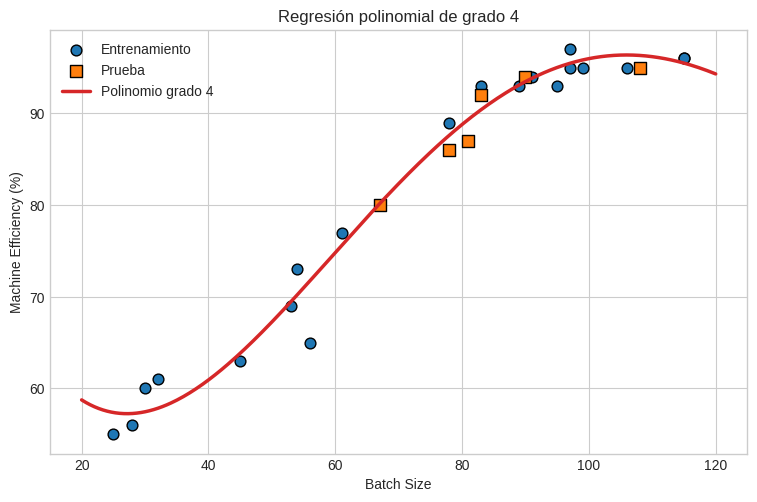

In [ ]:
# Creamos una malla densa de valores de x para dibujar una curva suave (con un poco de margen)
x_grid = np.linspace(X.min() - 5, X.max() + 5, 300).reshape(-1, 1)
# Predecimos la eficiencia sobre la malla
y_grid = model.predict(x_grid)

# Creamos la figura
plt.figure(figsize=(9, 5.5))
# Dibujamos los puntos de entrenamiento
plt.scatter(X_train, y_train, color="tab:blue", edgecolor="k", s=60, label="Entrenamiento")
# Dibujamos los puntos de prueba con otro color/marcador
plt.scatter(X_test, y_test, color="tab:orange", edgecolor="k", s=80, marker="s", label="Prueba")
# Dibujamos la curva polinomial ajustada
plt.plot(x_grid, y_grid, color="tab:red", linewidth=2.5, label=f"Polinomio grado {DEGREE}")
# Etiqueta del eje X
plt.xlabel("Batch Size")
# Etiqueta del eje Y
plt.ylabel("Machine Efficiency (%)")
# Título
plt.title(f"Regresión polinomial de grado {DEGREE}")
# Leyenda
plt.legend()
# Mostramos
plt.show()

## 4. Conclusiones

- La regresión polinomial es un caso particular de **regresión lineal por mínimos cuadrados**: lineal en los coeficientes, no lineal en $x$.
- El flujo completo con scikit-learn es: `StandardScaler → PolynomialFeatures → LinearRegression`, encapsulado en un `Pipeline` para evitar *data leakage*.
- Estandarizar $x$ reduce drásticamente el número de condición de $\mathbf{X}^\top\mathbf{X}$ (sección 3.10).
- Con un dataset pequeño (26 observaciones) hay que ser cauteloso: las métricas de prueba son inestables y un grado alto puede sobreajustar.
